In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# 1. Load Data
columns = ["airline", "flight_length", "speed", "daily_flight_time", "customers", 
           "operating_cost", "col6", "col7", "col8", "total_assets", "investments", "other"]
df = pd.read_csv("airline_costs.csv", names=columns)

In [11]:
# Fit Models
X1 = df[['flight_length', 'daily_flight_time']]
y1 = df['customers']
m1 = LinearRegression().fit(X1, y1)

X2 = df[['customers']]
y2 = df['total_assets']
m2 = LinearRegression().fit(X2, y2)

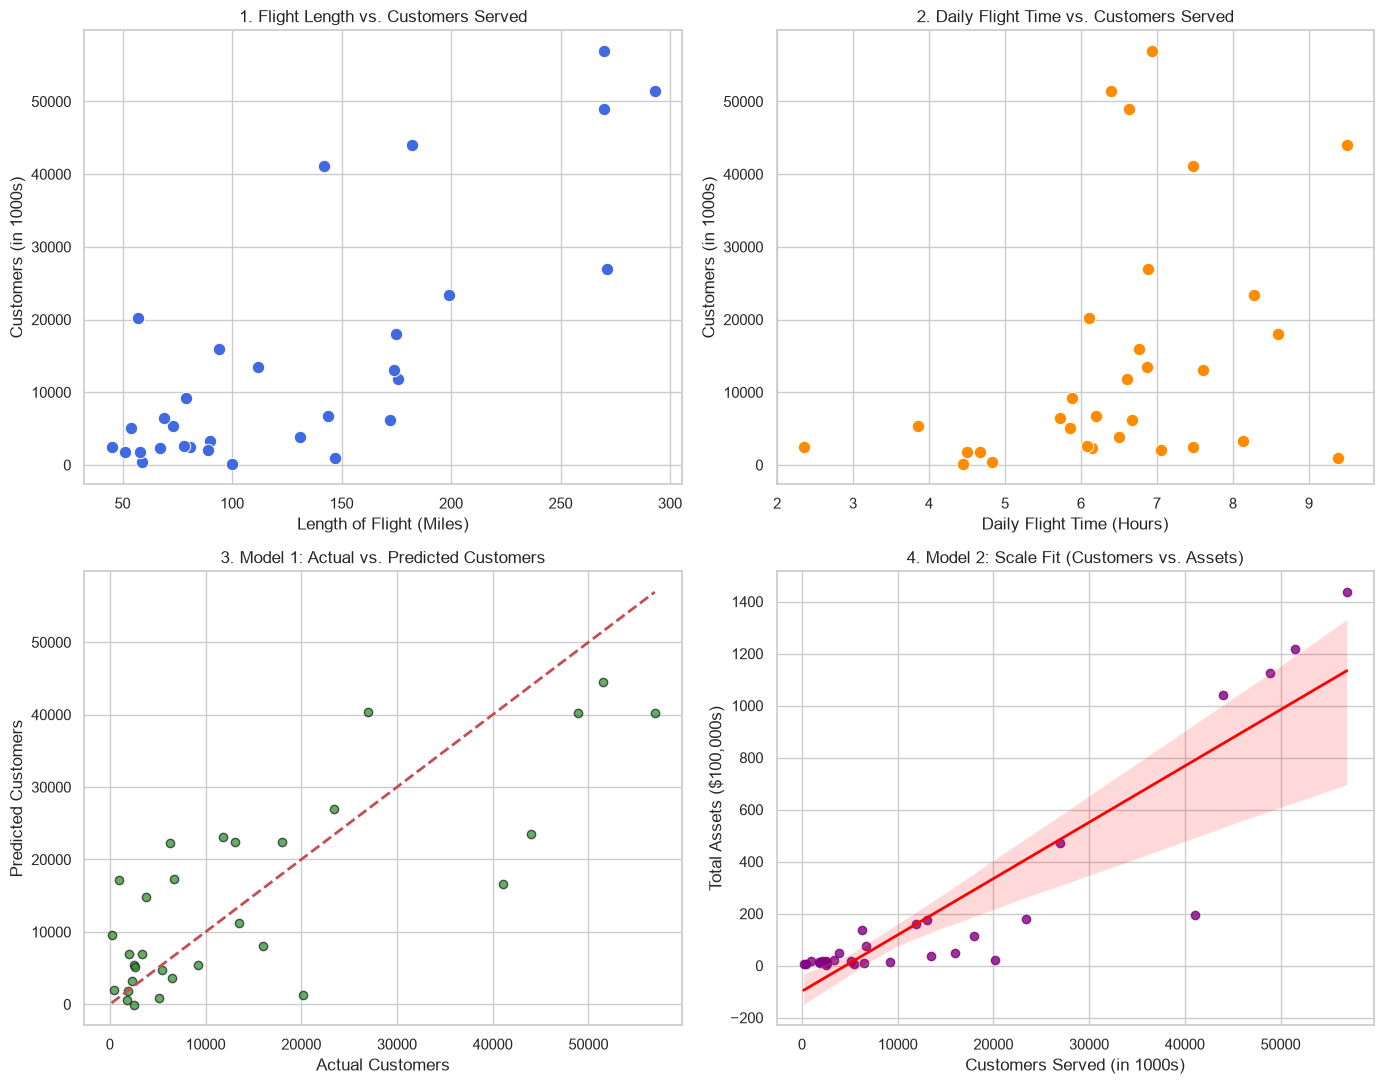

In [12]:
# Generate 4 Charts
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
sns.set_theme(style="whitegrid")

# Chart 1: Flight Length Influence
sns.scatterplot(data=df, x='flight_length', y='customers', ax=axes[0, 0], color='royalblue', s=80)
axes[0, 0].set_title('1. Flight Length vs. Customers Served')
axes[0, 0].set_xlabel('Length of Flight (Miles)')
axes[0, 0].set_ylabel('Customers (in 1000s)')

# Chart 2: Daily Flight Time Influence 
sns.scatterplot(data=df, x='daily_flight_time', y='customers', ax=axes[0, 1], color='darkorange', s=80)
axes[0, 1].set_title('2. Daily Flight Time vs. Customers Served')
axes[0, 1].set_xlabel('Daily Flight Time (Hours)')
axes[0, 1].set_ylabel('Customers (in 1000s)')

# Chart 3: Model 1 Sklearn Performance Accuracy
axes[1, 0].scatter(y1, m1.predict(X1), color='forestgreen', alpha=0.7, edgecolors='k')
axes[1, 0].plot([y1.min(), y1.max()], [y1.min(), y1.max()], 'r--', lw=2)
axes[1, 0].set_title('3. Model 1: Actual vs. Predicted Customers')
axes[1, 0].set_xlabel('Actual Customers')
axes[1, 0].set_ylabel('Predicted Customers')

# Chart 4: Model 2 Linear Regression Line Fit
sns.regplot(data=df, x='customers', y='total_assets', ax=axes[1, 1], color='purple', line_kws={'color': 'red', 'lw': 2})
axes[1, 1].set_title('4. Model 2: Scale Fit (Customers vs. Assets)')
axes[1, 1].set_xlabel('Customers Served (in 1000s)')
axes[1, 1].set_ylabel('Total Assets ($100,000s)')

plt.tight_layout()
plt.savefig('airline_regression_analysis.png', dpi=300)
plt.show()